Before adding neural network layers, let's understand PyTorch autograd on the simplest molecule in existence: two Hydrogen atoms ($H_2$) on a spring.

When two atoms are bonded, their potential energy behaves like a spring (Hooke's Law): $$E(r) = \frac{1}{2} k (r - r_0)^2$$

* $r_0 = 0.74\text{ Å}$ (the natural bond length of $H_2$).
* $k = 10.0$ (spring stiffness).

In [1]:
import torch 
import matplotlib.pyplot as plt 

In [7]:
from packaging import requirements
# Equilibrium bond length of H2 (in Angstroms)
r0 = 0.74 
k = 10.0 

# Two atoms along the x-axis: 
# Atom 0 at x = 0.0 
# Atom 1 at x = 1.2 Angstroms 
pos = torch.tensor([
    [0.0, 0.0, 0.0],
    [1.2, 0.0, 0.0]
], requires_grad=True)

print("Initial positions: \n", pos)

Initial positions: 
 tensor([[0.0000, 0.0000, 0.0000],
        [1.2000, 0.0000, 0.0000]], requires_grad=True)


Concept Check 14 (Hand Calculation vs. Autograd)
Look at that setup:

* Natural bond length $r_0 = 0.74\text{ Å}$.
* Current bond length $r = 1.20\text{ Å}$ (it is stretched!).

1. By hand: Is the potential energy higher or lower than at $r_0$?
2. Will the physical force on Atom 1 push it in the $+x$ direction (stretching further) or $-x$ direction (pulling back toward Atom 0)?
3. What should the force be on Atom 0?



1. The potential energy is higher than at $r_0$, because $r_0$ is the minimum potential energy. 
2. The physical force on Atom 1 will push in the -x direction (push Atom 1 closer to the orign)
3. (1/2) * 10 * (0.46 1e-10)^2 = 5 * 0.46^2 * 1e-20 = 5 * 0.46^2 * 6.242e-2 eV = around 0.06 eV

In [21]:
print(pos)
print(pos.shape)
print(pos[0])
print(pos[1])
print(pos[0, :])
print(pos[1, :])
print(pos[1, :] - pos[0, :])
print(torch.norm(pos[1] - pos[0]))
print(type(torch.norm(pos[1] - pos[0])))
print(r - r0)
print((r - r0).item())

tensor([[0.0000, 0.0000, 0.0000],
        [1.2000, 0.0000, 0.0000]], requires_grad=True)
torch.Size([2, 3])
tensor([0., 0., 0.], grad_fn=<SelectBackward0>)
tensor([1.2000, 0.0000, 0.0000], grad_fn=<SelectBackward0>)
tensor([0., 0., 0.], grad_fn=<SelectBackward0>)
tensor([1.2000, 0.0000, 0.0000], grad_fn=<SelectBackward0>)
tensor([1.2000, 0.0000, 0.0000], grad_fn=<SubBackward0>)
tensor(1.2000, grad_fn=<LinalgVectorNormBackward0>)
<class 'torch.Tensor'>
tensor(0.4600, grad_fn=<SubBackward0>)
0.46000003814697266


In [19]:
# 1. Compute bond distance r using Pytorch and vector math 
r = torch.norm(pos[1] - pos[0])
print(f"Bond distance r: {r.item():4f} Angstrongs")

# 2. Compute potential energy scalar E 
energy = 0.5 * k * (r - r0) ** 2 
print(f"Potential Energy E: {energy.item():4f}")

# 3. Compute physical forces via Autograd: F = -dE/dr 
forces = -torch.autograd.grad(outputs=energy, inputs=pos)[0]
print("Calculated Forces:\n", forces)

Bond distance r: 1.200000 Angstrongs
Potential Energy E: 1.058000
Calculated Forces:
 tensor([[ 4.6000, -0.0000, -0.0000],
        [-4.6000, -0.0000, -0.0000]])


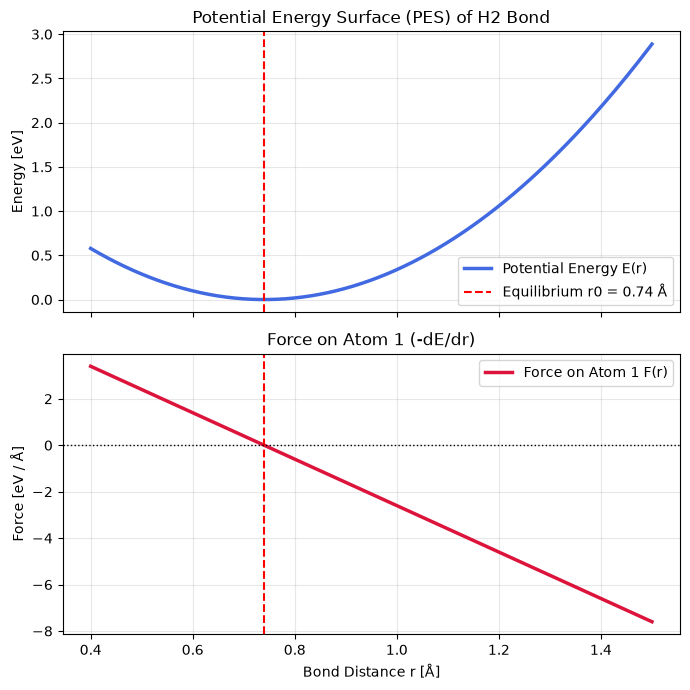

In [24]:
import numpy as np 

# Sample bond lengths from 0.4 Angstroms to 1.5 Angstroms 
r_vals = np.linspace(0.4, 1.5, 200)
e_vals = 0.5 * k * (r_vals - r0) ** 2 
f_vals = -k * (r_vals - r0) # restoring force on Atom 1 

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 7), sharex=True)

# Plot Potential Energy 
ax1.plot(r_vals, e_vals, color='royalblue', lw=2.5, 
label="Potential Energy E(r)")
ax1.axvline(r0, color='red', linestyle='--',
label=f"Equilibrium r0 = {r0} Å")
ax1.set_ylabel("Energy [eV]")
ax1.set_title("Potential Energy Surface (PES) of H2 Bond")
ax1.grid(True, alpha=0.3)
ax1.legend() 

# Plot Force 
ax2.plot(r_vals, f_vals, color='crimson', lw=2.5, 
label="Force on Atom 1 F(r)")
ax2.axvline(r0, color='red', linestyle='--')
ax2.axhline(0.0, color='black', linestyle=":", lw=1)
ax2.set_xlabel("Bond Distance r [Å]")
ax2.set_ylabel("Force [eV / Å]")
ax2.set_title("Force on Atom 1 (-dE/dr)")
ax2.grid(True, alpha=0.3)
ax2.legend() 

plt.tight_layout() 
plt.show()



Concept Check 15:

If we take both atoms and translate the entire molecule by $+10.0\text{ Å}$ along the $x$-axis (so Atom 0 moves from $x=0.0 \to 10.0$, and Atom 1 moves from $x=1.2 \to 11.2$):

1. Does the bond length $r$ change?
2. Does the energy $E$ change?
3. Do the internal forces $\vec{F}$ change?
4. What physical symmetry is this called, and why must any atomistic GNN guarantee it?


1. The bond length does not change, because both atoms are translated by the same amount. 
2. The energy does not change, because energy is a function of r (bond length), and r does not change. 
3. Internal forces do not change, because they are also a function of bond length. 
4. Thihs physical symmetry is called translation invariance. 

In [29]:
import torch.nn as nn 

# Embedding table: maps atomic numbers (1 to 100) to a 16-dimensional 
# feature vector 
hidden_dim = 16 
embedding_layer = nn.Embedding(
    num_embeddings=100, 
    embedding_dim=hidden_dim)

# Water molecule: Oxygen (8), Hydrogen (1), Hydrogen (1)
atomic_numbers = torch.tensor([8, 1, 1], dtype=torch.long)

# Pass atomic numbers through the embedding layer
h_atoms = embedding_layer(atomic_numbers)

print("Atomic number shape: ", atomic_numbers.shape)
print("Embedding features shape: ", h_atoms.shape)
print("First 4 features of Oxygen (Z=8):\n", h_atoms[0, :4])
print("First 4 features of Hydrogen 1: \n", h_atoms[1, :4])
print("First 4 features of Hydrogen 2: \n", h_atoms[2, :4])

Atomic number shape:  torch.Size([3])
Embedding features shape:  torch.Size([3, 16])
First 4 features of Oxygen (Z=8):
 tensor([-1.4122, -1.6959, -0.7785,  0.8460], grad_fn=<SliceBackward0>)
First 4 features of Hydrogen 1: 
 tensor([-0.1699, -0.2287, -0.8992, -1.2147], grad_fn=<SliceBackward0>)
First 4 features of Hydrogen 2: 
 tensor([-0.1699, -0.2287, -0.8992, -1.2147], grad_fn=<SliceBackward0>)


In [41]:
example_embedding_layer = nn.Embedding(5, 3)
print(example_embedding_layer)
print(example_embedding_layer(torch.tensor([0])))
print(example_embedding_layer(torch.tensor([0, 0])))
print(example_embedding_layer(torch.tensor([0, 1])))
print(example_embedding_layer(torch.tensor([0, 1])).shape)



Embedding(5, 3)
tensor([[-2.2141,  0.2003, -1.9323]], grad_fn=<EmbeddingBackward0>)
tensor([[-2.2141,  0.2003, -1.9323],
        [-2.2141,  0.2003, -1.9323]], grad_fn=<EmbeddingBackward0>)
tensor([[-2.2141,  0.2003, -1.9323],
        [ 1.3736,  0.7719,  2.0408]], grad_fn=<EmbeddingBackward0>)
torch.Size([2, 3])


Concept Check 16 (Why Embeddings?)
Looking at that output:

Why do neural networks convert element numbers into high-dimensional vectors (like 16, 128, or 512 dimensions) instead of just passing the integer atomic number $Z$ as a single float (e.g. $Z = 8.0$ for Oxygen)?

(Hint: Is an Oxygen atom mathematically "eight times" a Hydrogen atom? Is Carbon ($Z=6$) physically halfway between Beryllium ($Z=4$) and Oxygen ($Z=8$)?)

Neural networks convert element numbers into high-dimensional vectors, because the vectors are able to capture sematically rich meaningful information about the elements. For example, elements with certain types of similar properties may be close in some subspaces. By contrast, pure atomic numbers don't even catpure anything about periodicity. 

In [46]:
print(hidden_dim)
print(type(hidden_dim))
print(hidden_dim ** 2)
print(hidden_dim / 2)
print(hidden_dim // 2)

16
<class 'int'>
256
8.0
8


In [48]:
# Energy Head: Takes a 16-dim hidden vector and outputs a 
# single scalar energy per atom 
energy_head = nn.Sequential(
    nn.Linear(hidden_dim, hidden_dim), 
    nn.SiLU(), # Smooth non-linear activation function 
    nn.Linear(hidden_dim, 1) # Output: 1 scalar per atom
)

In [49]:
energy_head

Sequential(
  (0): Linear(in_features=16, out_features=16, bias=True)
  (1): SiLU()
  (2): Linear(in_features=16, out_features=1, bias=True)
)

In [55]:
print(energy_head)
print([p.numel() for p in energy_head.parameters()])

Sequential(
  (0): Linear(in_features=16, out_features=16, bias=True)
  (1): SiLU()
  (2): Linear(in_features=16, out_features=1, bias=True)
)
[256, 16, 16, 1]


In [59]:
for name, param in energy_head.named_parameters():
    print(name, param[:3])

0.weight tensor([[ 0.0817,  0.0036,  0.2486, -0.0461,  0.1647, -0.0570,  0.0514,  0.1497,
          0.1352, -0.0145, -0.1621,  0.0832, -0.1160, -0.1209, -0.1188,  0.2172],
        [ 0.0193, -0.2178,  0.1014, -0.2239, -0.0053, -0.0017, -0.0292,  0.2328,
         -0.0612,  0.1304,  0.0157,  0.0431, -0.2313, -0.0781, -0.1108,  0.0295],
        [ 0.1323,  0.1297, -0.0553,  0.0276, -0.1925,  0.0236,  0.1492,  0.1805,
          0.0717, -0.0418, -0.2079, -0.0474,  0.0296, -0.1632, -0.2426, -0.1454]],
       grad_fn=<SliceBackward0>)
0.bias tensor([ 0.2354, -0.2354, -0.0328], grad_fn=<SliceBackward0>)
2.weight tensor([[ 0.1827,  0.0095,  0.0613,  0.0902,  0.2467,  0.0673,  0.0225,  0.1182,
          0.1031,  0.0949, -0.1067,  0.0409,  0.1457,  0.0312, -0.2019, -0.1848]],
       grad_fn=<SliceBackward0>)
2.bias tensor([-0.2395], grad_fn=<SliceBackward0>)


tensor([[-1.4441, -0.1651, -0.3023],
        [-0.4797,  1.9978,  0.8073]])


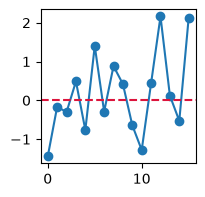

out_flat.shape: torch.Size([6, 1])


In [73]:
# PyTorch Linear layers apply only across the final dimension, 
# leaving leading batch and atom dimensions intact.

atoms_flat = torch.randn(6, hidden_dim)
print(atoms_flat[:2, :3])
plt.figure(figsize=(2, 2))
plt.plot(atoms_flat[0, :], marker='o')
plt.axhline(y=0, linestyle='--', color='crimson')
plt.show()

out_flat = energy_head(atoms_flat)
print(f"out_flat.shape: {out_flat.shape}")


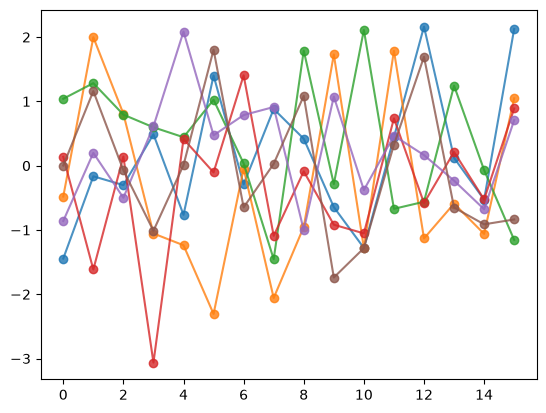

In [83]:
plt.plot(atoms_flat.T, marker='o', alpha=0.8)
plt.show()

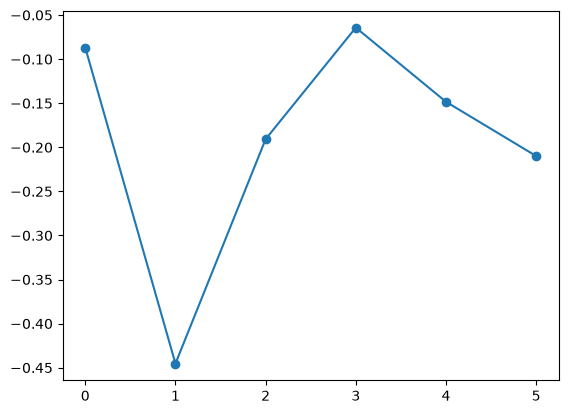

In [78]:
plt.plot(out_flat.detach().numpy(), marker='o')

In [86]:
atoms_batched = torch.randn(3, 5, hidden_dim)
out_batched = energy_head(atoms_batched)
print(f"input shape: {atoms_batched.shape}")
print(f"output shape: {out_batched.shape}")
print(out_batched)

input shape: torch.Size([3, 5, 16])
output shape: torch.Size([3, 5, 1])
tensor([[[ 1.2028e-01],
         [-1.1004e-01],
         [-1.4210e-01],
         [-3.0386e-01],
         [-3.0887e-01]],

        [[-3.5484e-01],
         [-1.8974e-01],
         [-1.4395e-04],
         [ 1.2250e-01],
         [-2.0775e-01]],

        [[-2.1801e-01],
         [-2.0095e-01],
         [-5.0641e-03],
         [-1.3085e-01],
         [ 1.4472e-02]]], grad_fn=<ViewBackward0>)


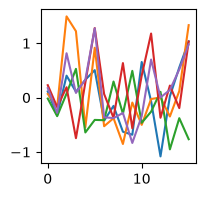

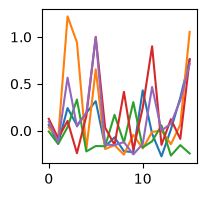

o1 shape: torch.Size([5, 1])
tensor([[-0.4972],
        [-0.3250],
        [-0.1531],
        [-0.2501],
        [-0.2885]], grad_fn=<AddmmBackward0>)


In [104]:
x = torch.randn(5, hidden_dim)
# x is 5 x 16 
# Each row represents the embedding of an atom 

h1 = energy_head[0](x)
plt.figure(figsize=(2, 2))
plt.plot(h1.T.detach().numpy())
plt.show() 

s1 = energy_head[1](h1)
plt.figure(figsize=(2, 2))
plt.plot(s1.T.detach().numpy())
plt.show() 

o1 = energy_head[2](s1)
print(f"o1 shape: {o1.shape}")
print(o1)

In [113]:
for name, param in energy_head.named_parameters():
    print("--- " * 10)
    print(name)
    print(f"mean: {param.mean():.3f}, std: {param.std():.3f}")

--- --- --- --- --- --- --- --- --- --- 
0.weight
mean: 0.006, std: 0.144
--- --- --- --- --- --- --- --- --- --- 
0.bias
mean: 0.006, std: 0.139
--- --- --- --- --- --- --- --- --- --- 
2.weight
mean: 0.045, std: 0.122
--- --- --- --- --- --- --- --- --- --- 
2.bias
mean: -0.239, std: nan


/var/folders/9c/38dwx_297yq_mj83fxbnvxrc0000gn/T/ipykernel_83702/2624006489.py:4: UserWarning: std(): degrees of freedom is <= 0. Correction should be strictly less than the reduction factor (input numel divided by output numel). (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/native/ReduceOps.cpp:1861.)
  print(f"mean: {param.mean():.3f}, std: {param.std():.3f}")


In [115]:
bias_tensor = energy_head[2].bias 
print(bias_tensor)
print(type(energy_head.named_parameters()))

Parameter containing:
tensor([-0.2395], requires_grad=True)
<class 'generator'>


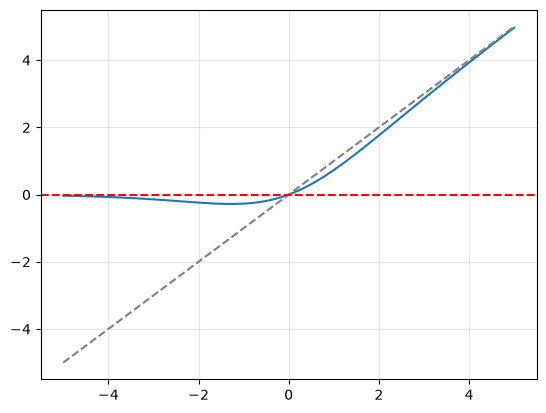

In [123]:
x = torch.linspace(-5, 5, 100)
s = energy_head[1](x)
plt.plot(x, s)
plt.plot(x, x, linestyle='--', color='grey')
plt.axhline(0, linestyle='--', color='red')
plt.grid(True, alpha=0.3)

h_atoms shape: (3, 16)
tensor([[-1.4122, -1.6959, -0.7785,  0.8460,  0.5199, -0.6401, -0.2338,  0.0133,
         -1.9503, -0.4188,  1.0881, -1.3440,  0.0410, -0.3690, -0.4036, -0.0343],
        [-0.1699, -0.2287, -0.8992, -1.2147,  1.0796, -0.3261, -1.3598, -1.3566,
         -0.6765,  1.8200, -0.8156, -0.4139,  1.6163, -0.1929, -0.4522,  1.2493],
        [-0.1699, -0.2287, -0.8992, -1.2147,  1.0796, -0.3261, -1.3598, -1.3566,
         -0.6765,  1.8200, -0.8156, -0.4139,  1.6163, -0.1929, -0.4522,  1.2493]],
       grad_fn=<EmbeddingBackward0>)


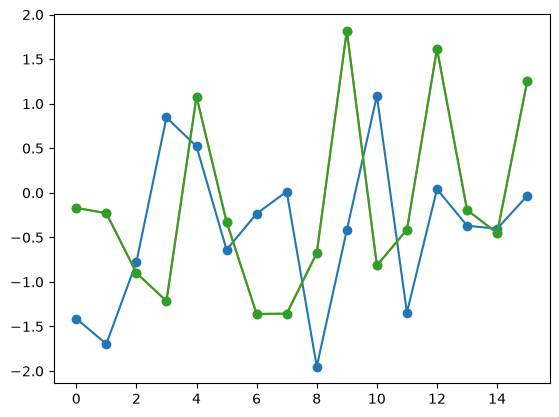

In [94]:
print(f"h_atoms shape: {tuple(h_atoms.shape)}")
print(h_atoms)
plt.plot(h_atoms.T.detach().numpy(), marker='o')

In [95]:
# 1. Predict energy contribution for each of our 3 atoms 
per_atom_energy = energy_head(h_atoms)
print("per_atom_energy shape: ", per_atom_energy.shape)
print("per_atom_energy values: ", per_atom_energy)

per_atom_energy shape:  torch.Size([3, 1])
per_atom_energy values:  tensor([[-0.1305],
        [-0.1660],
        [-0.1660]], grad_fn=<AddmmBackward0>)


In [97]:
# 2. Sum the atomic energies to get the total system energy
total_energy = per_atom_energy.sum() 
print("total energy: ", total_energy)
print("total energy: ", total_energy.item())

total energy:  tensor(-0.4625, grad_fn=<SumBackward0>)
total energy:  -0.46252578496932983


In [125]:
# Direct Force Head: Takes a 16-dim hidden vector and outputs 
# 3 coordinates (Fx, Fy, Fz)
direct_force_head = nn.Sequential(
    nn.Linear(hidden_dim, hidden_dim), 
    nn.SiLU(), 
    nn.Linear(hidden_dim, 3)
)

In [126]:
# Predict 3D force vectors directly for each of the 3 atoms 
predicted_forces = direct_force_head(h_atoms)
print(predicted_forces.shape)

torch.Size([3, 3])


In physics and chemistry, properties are either intensive (like temperature or pressure) or extensive (like mass or volume).

Is total potential energy an intensive or extensive property?
What would happen if a machine learning model computed total energy as an average (per_atom_energy.mean()) instead of a sum when moving from a small cluster of 5 gold atoms to a bulk slab of 5,000 gold atoms?
7:22 PM